# Complete Image Classification with PyTorch

This notebook contains the complete workflow for the plant-disease dataset:

1. imports and configuration;
2. dataset loading and inspection;
3. stratified splitting into training, validation and held-out test data;
4. a reusable, model-independent preprocessing pipeline;
5. a configurable PyTorch CNN;
6. Optuna tuning of convolutional depth, FC depth/width and learning rate;
7. final training with early stopping;
8. metric tracking in a history object;
9. accuracy and loss plots;
10. held-out test evaluation;
11. saving the model and preprocessing artifacts;
12. loading those artifacts and predicting a new image.

The notebook is delivered **unexecuted**: run the cells from top to bottom. The
shared helpers live in `plant_disease_inference.py`, which keeps the notebook
and the future website backend on the same preprocessing and architecture code.

**Budgets** are read from environment variables in the configuration cell. The
defaults are a practical starting point; increase them for a stronger model.

## 1. Imports and Configuration

This cell imports the libraries used throughout the notebook plus the shared
project module. Preprocessing, the configurable CNN and the prediction helpers
all come from `plant_disease_inference.py`, so training and deployment cannot
drift apart.

In [2]:
import json
import os
import random
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import PIL
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader, Subset
from torchinfo import summary
from torchvision import datasets

# Shared preprocessing, model-building and inference helpers.
from plant_disease_inference import (
    IMAGE_SIZE,
    MEAN,
    STD,
    ImagePreprocessingPipeline,
    build_cnn,
    load_preprocessing_pipeline,
    load_trained_model,
    model_config_from_hyperparameters,
    predict,
    predict_batch,
    save_model_checkpoint,
)

print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Optuna:", optuna.__version__, "| joblib:", joblib.__version__)

PyTorch: 2.13.0+cu132 | torchvision: 0.28.0+cu132
Optuna: 4.9.0 | joblib: 1.5.3


This cell fixes the random seed, selects the compute device, defines the
artifact paths and reads the experiment budgets. All budgets can be changed with
environment variables, for example `PLANT_HPO_TRIALS=10` or
`PLANT_FINAL_EPOCHS=15`, without editing the notebook.

In [3]:
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_DIR = Path.cwd()
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ARTIFACTS_DIR / "model.pt"
MODEL_CONFIG_PATH = ARTIFACTS_DIR / "model_config.json"
PIPELINE_PATH = ARTIFACTS_DIR / "preprocessing_pipeline.joblib"
CLASS_MAPPING_PATH = ARTIFACTS_DIR / "class_mapping.json"
HISTORY_PATH = ARTIFACTS_DIR / "training_history.json"

# Experiment budgets (override with environment variables if needed).
HPO_TRIALS = int(os.environ.get("PLANT_HPO_TRIALS", "10"))
HPO_EPOCHS = int(os.environ.get("PLANT_HPO_EPOCHS", "5"))
HPO_TRAIN_SIZE = int(os.environ.get("PLANT_HPO_TRAIN_SIZE", "6000"))
HPO_VAL_SIZE = int(os.environ.get("PLANT_HPO_VAL_SIZE", "1200"))

FINAL_EPOCHS = int(os.environ.get("PLANT_FINAL_EPOCHS", "100"))
FINAL_PATIENCE = int(os.environ.get("PLANT_FINAL_PATIENCE", "10"))
FINAL_TRAIN_SIZE = int(os.environ.get("PLANT_FINAL_TRAIN_SIZE", "0"))  # 0 = full folder

TEST_SIZE = 0.20
BATCH_SIZE = 64
# On Windows, set PLANT_NUM_WORKERS=0 if DataLoader worker startup fails.
NUM_WORKERS = int(os.environ.get("PLANT_NUM_WORKERS", "4"))


def set_seed(seed: int = SEED) -> None:
    """Make Python, NumPy and PyTorch runs reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Artifacts directory:", ARTIFACTS_DIR.resolve())
print(
    f"HPO budget: {HPO_TRIALS} trials x {HPO_EPOCHS} epochs "
    f"({HPO_TRAIN_SIZE} train / {HPO_VAL_SIZE} validation images)"
)
print(
    f"Final budget: up to {FINAL_EPOCHS} epochs, patience {FINAL_PATIENCE}, "
    f"train size {'full' if FINAL_TRAIN_SIZE == 0 else FINAL_TRAIN_SIZE}"
)

Device: cuda
GPU: NVIDIA GeForce RTX 2050
Artifacts directory: C:\Users\surya\Python_ML\PROJECTS\Plant Disease Classification (Project 03)\artifacts
HPO budget: 10 trials x 5 epochs (6000 train / 1200 validation images)
Final budget: up to 100 epochs, patience 10, train size full


## 2. Dataset Loading and Inspection

The two `ImageFolder` datasets are created without a transform so their images
can be inspected directly. The cell prints the dataset sizes, the number of
classes, the class balance and one sample image. The preprocessing transform is
attached after the split, in section 4.

In [4]:
TRAIN_DIR = Path(
    r"C:\Users\surya\Downloads\archive (12)\New Plant Diseases Dataset(Augmented)"
    r"\New Plant Diseases Dataset(Augmented)\train"
)
VALID_DIR = Path(
    r"C:\Users\surya\Downloads\archive (12)\New Plant Diseases Dataset(Augmented)"
    r"\New Plant Diseases Dataset(Augmented)\valid"
)

if not TRAIN_DIR.is_dir():
    raise FileNotFoundError(f"Training folder not found: {TRAIN_DIR}")
if not VALID_DIR.is_dir():
    raise FileNotFoundError(f"Validation folder not found: {VALID_DIR}")

# transform=None keeps images as PIL objects for inspection.
train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=None)
val_dataset = datasets.ImageFolder(root=VALID_DIR, transform=None)

if train_dataset.classes != val_dataset.classes:
    raise ValueError("Training and validation folders do not contain the same classes.")

class_names = list(train_dataset.classes)
class_to_idx = dict(train_dataset.class_to_idx)
idx_to_class = {index: name for index, name in enumerate(class_names)}
NUM_CLASSES = len(class_names)

train_targets = np.asarray(train_dataset.targets)
class_counts = np.bincount(train_targets, minlength=NUM_CLASSES)

print(f"Training images  : {len(train_dataset):,}")
print(f"Validation images: {len(val_dataset):,}")
print(f"Number of classes: {NUM_CLASSES}")
print(
    f"Images per class : min={class_counts.min()}, "
    f"max={class_counts.max()}, mean={class_counts.mean():.0f}"
)
print(f"First 5 classes  : {class_names[:5]}")

sample_image, sample_label = train_dataset[0]
print(
    f"Sample image     : PIL {sample_image.mode} {sample_image.size}, "
    f"label={sample_label} ({class_names[sample_label]})"
)

Training images  : 70,295
Validation images: 17,572
Number of classes: 38
Images per class : min=1642, max=2022, mean=1850
First 5 classes  : ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']
Sample image     : PIL RGB (256, 256), label=0 (Apple___Apple_scab)


## 3. Dataset Splitting

The dataset provides only `train` and `valid` folders. The training folder is
used for training, while the original validation folder is split **once** into a
validation set (80%) and a held-out test set (20%), stratified by class.

Small fixed subsets are also drawn for Optuna so every trial sees exactly the
same images. The test split is never used for tuning or checkpoint selection.

In [5]:
val_targets = np.asarray(val_dataset.targets)
val_indices_all = np.arange(len(val_dataset))

# Fixed, stratified 80/20 split of the original validation folder.
val_indices, test_indices = train_test_split(
    val_indices_all,
    test_size=TEST_SIZE,
    stratify=val_targets,
    random_state=SEED,
)

# Fixed tuning subset of the training folder.
hpo_train_count = min(HPO_TRAIN_SIZE, len(train_dataset))
if hpo_train_count < len(train_dataset):
    hpo_train_indices, _ = train_test_split(
        np.arange(len(train_dataset)),
        train_size=hpo_train_count,
        stratify=train_targets,
        random_state=SEED,
    )
else:
    hpo_train_indices = np.arange(len(train_dataset))

# Fixed tuning subset of the validation split.
hpo_val_count = min(HPO_VAL_SIZE, len(val_indices))
if hpo_val_count < len(val_indices):
    hpo_val_indices, _ = train_test_split(
        val_indices,
        train_size=hpo_val_count,
        stratify=val_targets[val_indices],
        random_state=SEED,
    )
else:
    hpo_val_indices = val_indices

# Final training uses the full training folder unless a smaller size is set.
if 0 < FINAL_TRAIN_SIZE < len(train_dataset):
    final_train_indices, _ = train_test_split(
        np.arange(len(train_dataset)),
        train_size=FINAL_TRAIN_SIZE,
        stratify=train_targets,
        random_state=SEED,
    )
    final_train_dataset = Subset(train_dataset, final_train_indices.tolist())
else:
    final_train_dataset = train_dataset

hpo_train_dataset = Subset(train_dataset, hpo_train_indices.tolist())
hpo_val_dataset = Subset(val_dataset, hpo_val_indices.tolist())
val_split_dataset = Subset(val_dataset, val_indices.tolist())
test_dataset = Subset(val_dataset, test_indices.tolist())


def make_loader(dataset, shuffle: bool) -> DataLoader:
    """Create a DataLoader with the project-wide settings."""
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == "cuda",
    )


hpo_train_loader = make_loader(hpo_train_dataset, shuffle=True)
hpo_val_loader = make_loader(hpo_val_dataset, shuffle=False)
final_train_loader = make_loader(final_train_dataset, shuffle=True)
val_loader = make_loader(val_split_dataset, shuffle=False)
test_loader = make_loader(test_dataset, shuffle=False)

if set(val_indices).intersection(set(test_indices)):
    raise RuntimeError("Validation and test splits overlap.")

print(f"Training folder            : {len(train_dataset):,}")
print(f"  HPO training subset      : {len(hpo_train_dataset):,}")
print(f"  Final training           : {len(final_train_dataset):,}")
print(f"Original validation folder : {len(val_dataset):,}")
print(f"  Final validation split   : {len(val_split_dataset):,}")
print(f"  HPO validation subset    : {len(hpo_val_dataset):,}")
print(f"  Held-out test split      : {len(test_dataset):,}")
print("Split check passed: test images are disjoint from validation.")

Training folder            : 70,295
  HPO training subset      : 6,000
  Final training           : 70,295
Original validation folder : 17,572
  Final validation split   : 14,057
  HPO validation subset    : 1,200
  Held-out test split      : 3,515
Split check passed: test images are disjoint from validation.


## 4. Image Preprocessing Pipeline

`ImagePreprocessingPipeline` resizes every image to 256×256, converts it to a
tensor and normalizes it with mean/std 0.5. Augmentation (horizontal flip and a
10° rotation) is enabled only for training. The pipeline contains no model code,
so it can be saved and loaded on its own.

The consistency check proves that the `ImageFolder` transform and the pipeline
used for new images produce exactly the same tensor.

In [6]:
preprocessing_pipeline = ImagePreprocessingPipeline(
    image_size=IMAGE_SIZE,
    mean=MEAN,
    std=STD,
)

train_transform = preprocessing_pipeline.as_torch_transform(augment=True)
eval_transform = preprocessing_pipeline.as_torch_transform(augment=False)

# Attach the transforms after splitting; every Subset delegates to these datasets.
train_dataset.transform = train_transform
val_dataset.transform = eval_transform

# Consistency check: dataset tensor and inference pipeline must match exactly.
check_index = int(test_indices[0])
check_path, _ = val_dataset.samples[check_index]
dataset_tensor, _ = val_dataset[check_index]
pipeline_tensor = preprocessing_pipeline.transform(check_path)

expected_shape = (3, *IMAGE_SIZE)
if tuple(dataset_tensor.shape) != expected_shape:
    raise RuntimeError(f"Unexpected tensor shape: {tuple(dataset_tensor.shape)}")
if not torch.allclose(dataset_tensor, pipeline_tensor):
    raise RuntimeError("Preprocessing drift between ImageFolder and the pipeline.")

print("Tensor shape:", tuple(pipeline_tensor.shape))
print("Tensor dtype:", pipeline_tensor.dtype)
print(f"Value range : [{pipeline_tensor.min():.3f}, {pipeline_tensor.max():.3f}]")

batch_tensor = preprocessing_pipeline.transform_batch(
    [check_path, val_dataset.samples[int(test_indices[1])][0]]
)
print("Batch shape :", tuple(batch_tensor.shape))
print("Pipeline config:")
print(json.dumps(preprocessing_pipeline.get_config(), indent=2))

Tensor shape: (3, 256, 256)
Tensor dtype: torch.float32
Value range : [-1.000, 1.000]
Batch shape : (2, 3, 256, 256)
Pipeline config:
{
  "type": "ImagePreprocessingPipeline",
  "image_size": [
    256,
    256
  ],
  "channels": 3,
  "color_mode": "RGB",
  "output_layout": "CHW",
  "output_dtype": "float32",
  "normalization": "pixel / 255, then (x - mean) / std",
  "mean": [
    0.5,
    0.5,
    0.5
  ],
  "std": [
    0.5,
    0.5,
    0.5
  ],
  "value_range": [
    -1.0,
    1.0
  ],
  "resize": "stretch to image_size (no center crop)",
  "augmentation": {
    "random_horizontal_flip_prob": 0.5,
    "random_rotation_degrees": 10.0,
    "applied_only_during_training": true
  }
}


## 5. Dynamic PyTorch CNN Architecture

`build_cnn` creates a CNN whose convolutional depth, hidden FC depth and FC
widths are configuration values. Each convolution block is Conv2d → BatchNorm →
ReLU → MaxPool, followed by global average pooling and the classifier. The output
layer is always `NUM_CLASSES`, derived from the dataset folders.

This cell builds a small example and prints its layer shapes and parameter
counts. The Optuna section builds the tuned variants from the same helper.

In [7]:
demo_hyperparameters = {
    "n_conv_layers": 5,
    "n_fc_layers": 2,
    "fc_units_1": 256,
    "fc_units_2": 128,
    "learning_rate": 0.001,
}
demo_config = model_config_from_hyperparameters(
    demo_hyperparameters, num_classes=NUM_CLASSES
)
demo_model = build_cnn(**demo_config).to(DEVICE)

print("Example architecture config:")
print(json.dumps(demo_config, indent=2))
summary(demo_model, input_size=(1, 3, *IMAGE_SIZE), device=str(DEVICE))

del demo_model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Example architecture config:
{
  "conv_channels": [
    32,
    64,
    128,
    256,
    512
  ],
  "hidden_units": [
    256,
    128
  ],
  "num_classes": 38,
  "in_channels": 3,
  "dropout": 0.4,
  "dropout_hidden": 0.3
}


## 6. Optuna Hyperparameter Tuning

These two helpers run one training epoch and one validation pass. They are shared
by every Optuna trial and by the final training loop, and they return the mean
loss and accuracy for the epoch.

In [8]:
def train_one_epoch(model, dataloader, criterion, optimizer, scaler, device):
    """Run one training epoch and return (mean loss, accuracy %)."""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in dataloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=scaler is not None):
            outputs = model(images)
            loss = criterion(outputs, labels)

        if scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, 100.0 * correct / total


def validate(model, dataloader, criterion, device):
    """Evaluate the model and return (mean loss, accuracy %)."""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=device.type == "cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return running_loss / total, 100.0 * correct / total


print("Training helpers are ready.")

Training helpers are ready.


Each trial samples a fresh architecture and learning rate, trains from
scratch on the fixed tuning subsets and reports validation accuracy after every
epoch.

| Hyperparameter | Search space |
| --- | --- |
| Convolutional layers | 3–7 |
| Hidden FC layers | 2–5 |
| Neurons per hidden FC layer | 64–256 (step 32) |
| Learning rate | log-uniform `0.00001` to `0.01` |

`MedianPruner` stops weak trials early. Selection uses validation accuracy only,
and the test split is never touched here.

In [9]:
def objective(trial: optuna.Trial) -> float:
    """Train one candidate CNN and return its best validation accuracy."""
    set_seed(SEED + trial.number)

    n_conv_layers = trial.suggest_int("n_conv_layers", 3, 7)
    n_fc_layers = trial.suggest_int("n_fc_layers", 2, 5)
    hidden_units = [
        trial.suggest_int(f"fc_units_{index}", 64, 256, step=32)
        for index in range(1, n_fc_layers + 1)
    ]
    learning_rate = trial.suggest_float("learning_rate", 0.00001, 0.01, log=True)

    trial_params = {
        "n_conv_layers": n_conv_layers,
        "n_fc_layers": n_fc_layers,
        **{
            f"fc_units_{index}": units
            for index, units in enumerate(hidden_units, start=1)
        },
        "learning_rate": learning_rate,
    }
    model_config = model_config_from_hyperparameters(
        trial_params, num_classes=NUM_CLASSES
    )
    trial.set_user_attr("model_config", model_config)

    model = build_cnn(**model_config).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(
        model.parameters(), lr=learning_rate, weight_decay=0.0001
    )
    scheduler = CosineAnnealingLR(optimizer, T_max=HPO_EPOCHS, eta_min=0.000001)
    scaler = torch.amp.GradScaler("cuda") if DEVICE.type == "cuda" else None

    best_accuracy = 0.0
    best_loss = float("inf")

    for epoch in range(HPO_EPOCHS):
        train_loss, train_acc = train_one_epoch(
            model, hpo_train_loader, criterion, optimizer, scaler, DEVICE
        )
        val_loss, val_acc = validate(model, hpo_val_loader, criterion, DEVICE)
        scheduler.step()

        best_accuracy = max(best_accuracy, val_acc)
        best_loss = min(best_loss, val_loss)

        print(
            f"  Trial {trial.number:02d} | epoch {epoch + 1}/{HPO_EPOCHS} | "
            f"train loss {train_loss:.4f} acc {train_acc:.2f}% | "
            f"val loss {val_loss:.4f} acc {val_acc:.2f}%"
        )

        trial.report(val_acc, epoch)
        if trial.should_prune():
            trial.set_user_attr("best_val_loss", best_loss)
            del model
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
            raise optuna.TrialPruned()

    trial.set_user_attr("best_val_loss", best_loss)
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return best_accuracy

The study uses the TPE sampler with two random startup trials and
maximizes validation accuracy. After the search, the best parameters and the
full trial table are printed.

In [10]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

sampler = optuna.samplers.TPESampler(seed=SEED, n_startup_trials=2)
pruner = optuna.pruners.MedianPruner(n_startup_trials=1, n_warmup_steps=0)
study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    pruner=pruner,
    study_name="plant_disease_cnn",
)

study.optimize(objective, n_trials=HPO_TRIALS, gc_after_trial=True)

best_params = dict(study.best_params)

print("\nBest trial:", study.best_trial.number)
print(f"Best validation accuracy (tuning subset): {study.best_value:.2f}%")
print("Best hyperparameters:")
for key, value in best_params.items():
    print(f"  {key}: {value}")

trials_table = study.trials_dataframe(
    attrs=("number", "value", "state", "params")
)
print("\nAll trials:")
print(trials_table.to_string(index=False))

  Trial 00 | epoch 1/5 | train loss 3.4761 acc 4.75% | val loss 3.3220 acc 5.08%
  Trial 00 | epoch 2/5 | train loss 3.2811 acc 6.90% | val loss 3.1357 acc 10.25%
  Trial 00 | epoch 3/5 | train loss 3.1359 acc 9.05% | val loss 3.0103 acc 12.75%
  Trial 00 | epoch 4/5 | train loss 2.9916 acc 10.77% | val loss 2.7937 acc 15.25%
  Trial 00 | epoch 5/5 | train loss 2.8653 acc 12.45% | val loss 2.7259 acc 17.50%
  Trial 01 | epoch 1/5 | train loss 3.6312 acc 3.70% | val loss 3.6121 acc 5.83%
  Trial 01 | epoch 2/5 | train loss 3.5896 acc 4.93% | val loss 3.5258 acc 7.33%
  Trial 02 | epoch 1/5 | train loss 3.4533 acc 4.45% | val loss 3.2916 acc 6.33%
  Trial 02 | epoch 2/5 | train loss 3.2294 acc 6.87% | val loss 3.1823 acc 8.92%
  Trial 03 | epoch 1/5 | train loss 3.0961 acc 13.23% | val loss 2.6058 acc 27.08%
  Trial 03 | epoch 2/5 | train loss 2.5457 acc 24.35% | val loss 2.2883 acc 29.42%
  Trial 03 | epoch 3/5 | train loss 2.2199 acc 33.10% | val loss 1.9602 acc 42.33%
  Trial 03 | epo

## 7. Final Model Training

The best parameters are converted into a concrete architecture, and the model is
trained from scratch on the training set. Validation loss decides when to save
`model.pt` and when to stop early; the held-out test set is still untouched.

Every epoch appends training/validation loss and accuracy to the `history`
object.

In [11]:
best_model_config = model_config_from_hyperparameters(
    best_params, num_classes=NUM_CLASSES
)
best_learning_rate = float(best_params["learning_rate"])

print("Best hyperparameters:")
print(json.dumps(best_params, indent=2))
print("Final architecture:")
print(json.dumps(best_model_config, indent=2))

set_seed(SEED)
final_model = build_cnn(**best_model_config).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    final_model.parameters(), lr=best_learning_rate, weight_decay=0.0001
)
scheduler = CosineAnnealingLR(optimizer, T_max=FINAL_EPOCHS, eta_min=0.000001)
scaler = torch.amp.GradScaler("cuda") if DEVICE.type == "cuda" else None

history = {
    "epochs": [],
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "learning_rate": [],
    "epoch_seconds": [],
    "best_epoch": 0,
    "best_val_loss": None,
    "epochs_run": 0,
    "epochs_planned": FINAL_EPOCHS,
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(FINAL_EPOCHS):
    start_time = time.time()
    current_lr = optimizer.param_groups[0]["lr"]

    train_loss, train_acc = train_one_epoch(
        final_model, final_train_loader, criterion, optimizer, scaler, DEVICE
    )
    val_loss, val_acc = validate(final_model, val_loader, criterion, DEVICE)
    scheduler.step()
    elapsed = time.time() - start_time

    history["epochs"].append(epoch + 1)
    history["train_loss"].append(float(train_loss))
    history["train_acc"].append(float(train_acc))
    history["val_loss"].append(float(val_loss))
    history["val_acc"].append(float(val_acc))
    history["learning_rate"].append(float(current_lr))
    history["epoch_seconds"].append(float(elapsed))
    history["epochs_run"] = epoch + 1

    print(
        f"Epoch [{epoch + 1:02d}/{FINAL_EPOCHS:02d}] ({elapsed:.1f}s) | "
        f"lr {current_lr:.6f} | "
        f"train loss {train_loss:.4f} acc {train_acc:.2f}% | "
        f"val loss {val_loss:.4f} acc {val_acc:.2f}%"
    )

    if val_loss < best_val_loss - 0.0001:
        best_val_loss = float(val_loss)
        best_epoch = epoch + 1
        epochs_without_improvement = 0
        history["best_epoch"] = best_epoch
        history["best_val_loss"] = best_val_loss

        save_model_checkpoint(
            final_model,
            MODEL_PATH,
            model_config=best_model_config,
            class_names=class_names,
            class_to_idx=class_to_idx,
            preprocessing_config=preprocessing_pipeline.get_config(),
            extra={
                "best_hyperparameters": best_params,
                "epoch": best_epoch,
                "val_loss": best_val_loss,
                "val_acc": float(val_acc),
                "training_history": history,
            },
        )
        print(f"  Validation loss improved; checkpoint saved to {MODEL_PATH.name}")
    else:
        epochs_without_improvement += 1
        print(
            f"  No improvement "
            f"({epochs_without_improvement}/{FINAL_PATIENCE})."
        )
        if epochs_without_improvement >= FINAL_PATIENCE:
            print("  Early stopping.")
            break

print(
    f"\nFinished after {history['epochs_run']} epoch(s). "
    f"Best epoch: {best_epoch} | best validation loss: {best_val_loss:.4f}"
)

Best hyperparameters:
{
  "n_conv_layers": 3,
  "n_fc_layers": 2,
  "fc_units_1": 256,
  "fc_units_2": 64,
  "learning_rate": 0.005583595034170054
}
Final architecture:
{
  "conv_channels": [
    32,
    64,
    128
  ],
  "hidden_units": [
    256,
    64
  ],
  "num_classes": 38,
  "in_channels": 3,
  "dropout": 0.4,
  "dropout_hidden": 0.3
}
Epoch [01/100] (237.5s) | lr 0.005584 | train loss 2.0074 acc 39.54% | val loss 1.0962 acc 65.35%
  Validation loss improved; checkpoint saved to model.pt
Epoch [02/100] (292.3s) | lr 0.005582 | train loss 1.3460 acc 58.72% | val loss 0.8202 acc 73.56%
  Validation loss improved; checkpoint saved to model.pt
Epoch [03/100] (302.0s) | lr 0.005578 | train loss 1.1371 acc 65.03% | val loss 0.6527 acc 79.13%
  Validation loss improved; checkpoint saved to model.pt
Epoch [04/100] (301.5s) | lr 0.005571 | train loss 0.9889 acc 69.67% | val loss 0.4706 acc 85.67%
  Validation loss improved; checkpoint saved to model.pt
Epoch [05/100] (303.5s) | lr 0.00

## 8. Training and Validation Metrics

The `history` dictionary stores one list per metric plus the best epoch and the
number of epochs actually run. This cell prints the recorded values in a compact
table; the next section plots the same data.

In [12]:
header = (
    f"{'Epoch':>5} | {'Train loss':>10} | {'Train acc':>9} | "
    f"{'Val loss':>9} | {'Val acc':>8} | {'Seconds':>7}"
)
print(header)
print("-" * len(header))
for index, epoch in enumerate(history["epochs"]):
    print(
        f"{epoch:>5} | {history['train_loss'][index]:>10.4f} | "
        f"{history['train_acc'][index]:>8.2f}% | "
        f"{history['val_loss'][index]:>9.4f} | "
        f"{history['val_acc'][index]:>7.2f}% | "
        f"{history['epoch_seconds'][index]:>7.1f}"
    )

print(
    f"\nBest epoch: {history['best_epoch']} | "
    f"best validation loss: {history['best_val_loss']:.4f}"
)
print(f"Best validation accuracy: {max(history['val_acc']):.2f}%")

Epoch | Train loss | Train acc |  Val loss |  Val acc | Seconds
---------------------------------------------------------------
    1 |     2.0074 |    39.54% |    1.0962 |   65.35% |   237.5
    2 |     1.3460 |    58.72% |    0.8202 |   73.56% |   292.3
    3 |     1.1371 |    65.03% |    0.6527 |   79.13% |   302.0
    4 |     0.9889 |    69.67% |    0.4706 |   85.67% |   301.5
    5 |     0.8888 |    72.81% |    0.5134 |   83.57% |   303.5
    6 |     0.8104 |    74.98% |    0.3600 |   88.48% |   302.5
    7 |     0.7507 |    76.93% |    0.3724 |   87.96% |   299.5
    8 |     0.7019 |    78.37% |    0.3185 |   89.88% |   301.8
    9 |     0.6681 |    79.49% |    0.2903 |   90.64% |   280.6
   10 |     0.6293 |    80.86% |    0.2754 |   91.05% |   237.4
   11 |     0.6021 |    81.70% |    0.3244 |   89.52% |   235.0
   12 |     0.5780 |    82.40% |    0.2155 |   93.14% |   303.5
   13 |     0.5564 |    83.13% |    0.2114 |   92.94% |   284.8
   14 |     0.5368 |    83.89% |    0.17

## 9. Accuracy and Loss Visualization

Two side-by-side plots show training versus validation accuracy and training
versus validation loss for every completed epoch. A widening gap between the
training and validation curves is an early sign of overfitting.

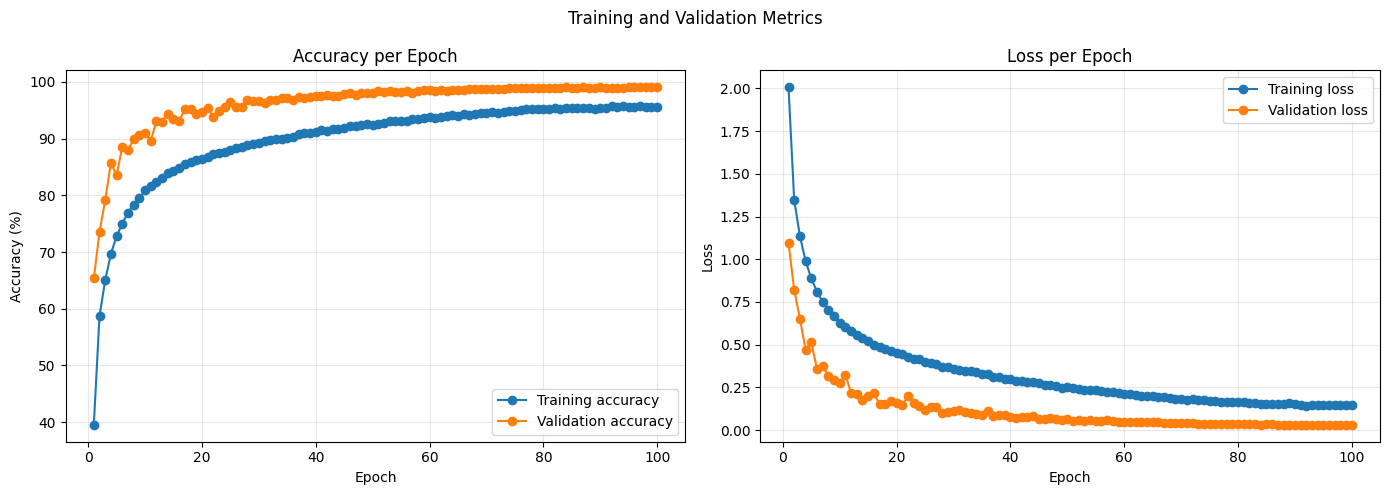

In [13]:
epochs = history["epochs"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["train_acc"], marker="o", label="Training accuracy")
axes[0].plot(epochs, history["val_acc"], marker="o", label="Validation accuracy")
axes[0].set_title("Accuracy per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, history["train_loss"], marker="o", label="Training loss")
axes[1].plot(epochs, history["val_loss"], marker="o", label="Validation loss")
axes[1].set_title("Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.suptitle("Training and Validation Metrics")
plt.tight_layout()
plt.show()

## 10. Test Evaluation

The best `model.pt` checkpoint is reloaded and evaluated once on the held-out
test split. The cell prints overall accuracy, a per-class report and the five
most frequent confusions.

In [14]:
best_model, best_checkpoint = load_trained_model(MODEL_PATH, device=DEVICE)

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=DEVICE.type == "cuda"):
            outputs = best_model(images)
        all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

all_predictions = np.asarray(all_predictions)
all_labels = np.asarray(all_labels)

test_accuracy = float((all_predictions == all_labels).mean() * 100.0)
report_dict = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0,
    output_dict=True,
)

test_metrics = {
    "accuracy_percent": test_accuracy,
    "macro_precision": float(report_dict["macro avg"]["precision"]),
    "macro_recall": float(report_dict["macro avg"]["recall"]),
    "macro_f1": float(report_dict["macro avg"]["f1-score"]),
    "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
    "n_test_images": int(len(all_labels)),
}

print(f"Test accuracy: {test_accuracy:.2f}% on {len(all_labels):,} held-out images\n")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        digits=4,
        zero_division=0,
    )
)

confusion = confusion_matrix(all_labels, all_predictions)
off_diagonal = confusion.copy()
np.fill_diagonal(off_diagonal, 0)
top_positions = np.argsort(off_diagonal.ravel())[-5:][::-1]

print("Most frequent confusions (true -> predicted):")
for position in top_positions:
    true_index, predicted_index = np.unravel_index(position, confusion.shape)
    count = int(off_diagonal[true_index, predicted_index])
    if count:
        print(f"  {class_names[true_index]} -> {class_names[predicted_index]}: {count}")

Test accuracy: 99.06% on 3,515 held-out images

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     1.0000    1.0000    1.0000       101
                                 Apple___Black_rot     1.0000    1.0000    1.0000        99
                          Apple___Cedar_apple_rust     0.9888    1.0000    0.9944        88
                                   Apple___healthy     1.0000    1.0000    1.0000       101
                               Blueberry___healthy     1.0000    1.0000    1.0000        91
          Cherry_(including_sour)___Powdery_mildew     1.0000    1.0000    1.0000        84
                 Cherry_(including_sour)___healthy     0.9891    1.0000    0.9945        91
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9494    0.9146    0.9317        82
                       Corn_(maize)___Common_rust_     1.0000    1.0000    1.0000        95
               Corn_(maize)___N

## 11. Saving the Model and Pipeline

Five artifacts are written to `artifacts/`:

| File | Contents |
| --- | --- |
| `model.pt` | best `state_dict` + architecture config + class names + metrics |
| `model_config.json` | best hyperparameters, architecture, input contract and metrics |
| `preprocessing_pipeline.joblib` | reusable pipeline with no model code |
| `class_mapping.json` | class names and index ↔ name mappings |
| `training_history.json` | per-epoch training and validation metrics |

The pipeline and the model are stored separately so a website backend can load
either one without the other.

In [15]:
# 1. Preprocessing pipeline, independent of the model.
preprocessing_pipeline.save(PIPELINE_PATH)

# 2. Model checkpoint: best state_dict plus the configuration needed to rebuild it.
checkpoint = torch.load(MODEL_PATH, map_location="cpu", weights_only=False)
checkpoint["state_dict"] = {
    key: value.detach().cpu() for key, value in checkpoint["state_dict"].items()
}
checkpoint["class_names"] = class_names
checkpoint["class_to_idx"] = class_to_idx
checkpoint["preprocessing_config"] = preprocessing_pipeline.get_config()
checkpoint["best_hyperparameters"] = best_params
checkpoint["test_metrics"] = test_metrics
checkpoint["training_history"] = history
torch.save(checkpoint, MODEL_PATH)

# 3. model_config.json: architecture, hyperparameters and input contract.
model_config_document = {
    "project": "Plant Disease Classification",
    "task": "single-label image classification",
    "num_classes": NUM_CLASSES,
    "class_names": class_names,
    "class_to_idx": class_to_idx,
    "model_file": MODEL_PATH.name,
    "preprocessing_pipeline_file": PIPELINE_PATH.name,
    "class_mapping_file": CLASS_MAPPING_PATH.name,
    "model_config": best_model_config,
    "best_hyperparameters": best_params,
    "input": {
        "image_size": list(IMAGE_SIZE),
        "channels": 3,
        "color_mode": "RGB",
        "layout": "NCHW",
        "dtype": "float32",
        "mean": list(MEAN),
        "std": list(STD),
        "value_range": [-1.0, 1.0],
        "batch_dimension_required": True,
    },
    "preprocessing": preprocessing_pipeline.get_config(),
    "training": {
        "seed": SEED,
        "optimizer": "AdamW",
        "weight_decay": 0.0001,
        "scheduler": "CosineAnnealingLR",
        "loss": "CrossEntropyLoss",
        "batch_size": BATCH_SIZE,
        "epochs_planned": FINAL_EPOCHS,
        "epochs_run": history["epochs_run"],
        "best_epoch": history["best_epoch"],
        "train_images": len(final_train_dataset),
        "validation_images": len(val_split_dataset),
        "test_images": len(test_dataset),
    },
    "test_metrics": test_metrics,
    "library_versions": {
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "numpy": np.__version__,
        "pillow": PIL.__version__,
        "joblib": joblib.__version__,
    },
}
with MODEL_CONFIG_PATH.open("w", encoding="utf-8") as handle:
    json.dump(model_config_document, handle, indent=2, ensure_ascii=False)

# 4. class_mapping.json: names and both index directions.
class_mapping = {
    "num_classes": NUM_CLASSES,
    "class_names": class_names,
    "class_to_idx": class_to_idx,
    "idx_to_class": {str(index): name for index, name in idx_to_class.items()},
}
with CLASS_MAPPING_PATH.open("w", encoding="utf-8") as handle:
    json.dump(class_mapping, handle, indent=2, ensure_ascii=False)

# 5. training_history.json: per-epoch metrics.
with HISTORY_PATH.open("w", encoding="utf-8") as handle:
    json.dump(history, handle, indent=2)

print("Saved artifacts:")
for path in sorted(ARTIFACTS_DIR.iterdir()):
    print(f"  {path.name:32s} {path.stat().st_size / 1024:9.1f} KiB")

Saved artifacts:
  class_mapping.json                     4.2 KiB
  model.pt                             586.0 KiB
  model_config.json                      5.1 KiB
  preprocessing_pipeline.joblib          0.2 KiB
  training_history.json                 15.9 KiB


## 12. Loading the Saved Artifacts and Predicting

This cell behaves like a backend: it loads `model.pt` and
`preprocessing_pipeline.joblib` from disk, processes a raw image and returns the
top-3 predictions. Set `new_image_path` to any image to test your own file; when
it is `None`, a held-out test image is used.

Model input contract: `(1, 3, 256, 256)`, RGB, `float32`, range `[-1, 1]`.

Image        : 6d4ccc3a-c410-4d67-8858-e411ad1c4486___FREC_Pwd.M 5007.JPG
Input shape  : (3, 256, 256)
Input dtype  : torch.float32
Input range  : [-1.000, 1.000]
True class   : Cherry_(including_sour)___Powdery_mildew
Predicted    : Cherry_(including_sour)___Powdery_mildew
Confidence   : 100.00%
Top-3:
  Cherry_(including_sour)___Powdery_mildew: 100.00%
  Tomato___Late_blight: 0.00%
  Peach___Bacterial_spot: 0.00%

Batch shape: (3, 3, 256, 256)
  6d4ccc3a-c410-4d67-8858-e411ad1c4486___FREC_Pwd.M 5007. -> Cherry_(including_sour)___Powdery_mildew (100.00%)
  cb428fa4-5b33-4ac6-b473-009c6f48a801___FAM_L.Blight 476 -> Grape___Leaf_blight_(Isariopsis_Leaf_Spot) (100.00%)
  cf21ccf7-0ad0-44cb-b541-a03d3921afcf___GHLB2 Leaf 8798. -> Tomato___Late_blight (95.39%)


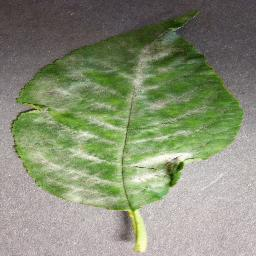

In [16]:
loaded_pipeline = load_preprocessing_pipeline(PIPELINE_PATH)
loaded_model, loaded_checkpoint = load_trained_model(MODEL_PATH, device=DEVICE)

with MODEL_CONFIG_PATH.open("r", encoding="utf-8") as handle:
    loaded_config = json.load(handle)
with CLASS_MAPPING_PATH.open("r", encoding="utf-8") as handle:
    loaded_mapping = json.load(handle)

loaded_class_names = loaded_config["class_names"]
if loaded_class_names != loaded_mapping["class_names"]:
    raise RuntimeError(
        "class_mapping.json and model_config.json disagree on class order."
    )

# Set this to any image path; None uses one held-out test image.
new_image_path = None
if new_image_path is None:
    sample_position = int(test_indices[0])
    new_image_path = val_dataset.samples[sample_position][0]
    true_class = class_names[val_dataset.samples[sample_position][1]]
else:
    true_class = None

processed_image = loaded_pipeline.transform(new_image_path)

print("Image        :", Path(new_image_path).name)
print("Input shape  :", tuple(processed_image.shape))
print("Input dtype  :", processed_image.dtype)
print(f"Input range  : [{processed_image.min():.3f}, {processed_image.max():.3f}]")

prediction = predict(
    loaded_model,
    processed_image,
    class_names=loaded_class_names,
    top_k=3,
)

if true_class is not None:
    print("True class   :", true_class)
print("Predicted    :", prediction["predicted_class"])
print(f"Confidence   : {prediction['confidence'] * 100:.2f}%")
print("Top-3:")
for item in prediction["top_k"]:
    print(f"  {item['class_name']}: {item['probability'] * 100:.2f}%")

# Batch demonstration with the same independently loaded artifacts.
batch_paths = [
    val_dataset.samples[int(index)][0] for index in test_indices[:3]
]
batch_tensor = loaded_pipeline.transform_batch(batch_paths)
batch_results = predict_batch(
    loaded_model,
    batch_tensor,
    class_names=loaded_class_names,
    top_k=1,
)

print("\nBatch shape:", tuple(batch_tensor.shape))
for path, result in zip(batch_paths, batch_results):
    print(
        f"  {Path(path).name[:55]:55s} -> "
        f"{result['predicted_class']} "
        f"({result['confidence'] * 100:.2f}%)"
    )

# Display the inspected image in Jupyter.
Image.open(new_image_path)

## Next Steps

The notebook ends with ready-to-serve artifacts. For a website, copy
`plant_disease_inference.py` and the files inside `artifacts/`, load them once at
startup and reuse them for every request. The website itself is intentionally not
built here.